In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU in Runtime settings.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:
!pip -q install -U datasets huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 20.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.


In [ ]:
import torch
import datasets
import huggingface_hub

print("GPU available:", torch.cuda.is_available())
print("Datasets version:", datasets.__version__)
print("Hugging Face Hub version:", huggingface_hub.__version__)

GPU available: True
Datasets version: 5.1.0
Hugging Face Hub version: 2.2.0


In [ ]:
from datasets import load_dataset

dataset = load_dataset("mohanty/PlantVillage", name="default")

print("Training images:", len(dataset["train"]))
print("Test images:", len(dataset["test"]))
print("\nTraining columns:", dataset["train"].column_names)

README.md:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

grayscale_train.txt:   0%|          | 0.00/4.28M [00:00<?, ?B/s]

segmented_train.txt:   0%|          | 0.00/4.86M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

grayscale_test.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

segmented_test.txt:   0%|          | 0.00/1.28M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Training images: 129783
Test images: 33133

Training columns: ['text']


In [ ]:
from collections import Counter

maize_paths = [
    path for path in dataset["train"]["text"]
    if path.startswith("raw/color/Corn_(maize)___")
]

class_counts = Counter(
    path.split("/")[2].replace("Corn_(maize)___", "")
    for path in maize_paths
)

print("Total maize training images:", len(maize_paths))
print("\nImages per class:")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

Total maize training images: 3058

Images per class:
Cercospora_leaf_spot Gray_leaf_spot: 406
Common_rust_: 975
Northern_Leaf_Blight: 765
healthy: 912


In [ ]:
from huggingface_hub import hf_hub_download
import os

zip_path = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    repo_type="dataset",
    filename="data.zip"
)

print("Archive downloaded successfully.")
print("File size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

Archive downloaded successfully.
File size: 2.03 GB


In [ ]:
import zipfile
from pathlib import Path

train_dir = Path("/content/maize_train")
train_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    manifest = z.read("color_train.txt").decode("utf-8")

    maize_paths = [
        line.strip()
        for line in manifest.splitlines()
        if line.strip().startswith("raw/color/Corn_(maize)___")
    ]

    for i, path in enumerate(maize_paths, start=1):
        destination = train_dir / Path(path).relative_to("raw/color")
        destination.parent.mkdir(parents=True, exist_ok=True)

        with z.open(path) as source, open(destination, "wb") as target:
            target.write(source.read())

        if i % 500 == 0:
            print(f"Extracted {i}/{len(maize_paths)} images")

print("\nExtraction complete!")
print("Total images extracted:", sum(1 for p in train_dir.rglob("*") if p.is_file()))
print("Training directory:", train_dir)

KeyError: "There is no item named 'color_train.txt' in the archive"

In [ ]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    matches = [
        name for name in z.namelist()
        if name.endswith("color_train.txt")
    ]

    print("Matching files:", matches)

Matching files: []


In [ ]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as z:
    print("First 30 entries in the archive:\n")
    for name in z.namelist()[:30]:
        print(name)

First 30 entries in the archive:

raw/
raw/color/
raw/color/Raspberry___healthy/
raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG
raw/color/Raspberry___healthy/d1387960-14d6-4654-ad5c-b92afa86ff6a___Mary_HL 9262.JPG
raw/color/Raspberry___healthy/fafac0a9-e5ba-420d-9dbe-034942f845b9___Mary_HL 9201.JPG
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
raw/color/Raspberry___healthy/fe1c1683-06cc-49c5-b86a-a41fb36f058b___Mary_HL 6249.JPG
raw/color/Raspberry___healthy/e621e3c3-842a-4489-b931-89f05c254cbe___Mary_HL 9347.JPG
raw/color/Raspberry___healthy/b8a96dea-8442-4855-9fdf-c29c9d4eca5a___Mary_HL 6398.JPG
raw/color/Raspberry___healthy/42428dcc-fefc-46dd-b209-150fbeaf4862___Mary_HL 6397.JPG
raw/color/Raspberry___healthy/076d909d-cfca-47ce-a8d1-479bb77c4bab___Mary_HL 6294.JPG
raw/color/Raspberry___healthy/27ef7a65-771c-4eab-9169-03a5fa121c71___Mary_HL 9195.JPG
raw/color/Raspberry___healthy/895d0a2d-5fda-47ca-af52-5cf4f

In [ ]:
import zipfile
from pathlib import Path

train_dir = Path("/content/maize_train")
train_dir.mkdir(parents=True, exist_ok=True)

maize_paths = [
    path for path in dataset["train"]["text"]
    if path.startswith("raw/color/Corn_(maize)___")
]

with zipfile.ZipFile(zip_path, "r") as z:
    available = set(z.namelist())

    missing = [p for p in maize_paths if p not in available]
    if missing:
        raise FileNotFoundError(
            f"{len(missing)} training images are missing from the ZIP."
        )

    for i, path in enumerate(maize_paths, start=1):
        destination = train_dir / Path(path).relative_to("raw/color")
        destination.parent.mkdir(parents=True, exist_ok=True)

        with z.open(path) as src, open(destination, "wb") as dst:
            dst.write(src.read())

        if i % 500 == 0:
            print(f"Extracted {i}/{len(maize_paths)} images")

print("\nExtraction complete.")
print("Total images:", sum(1 for p in train_dir.rglob("*") if p.is_file()))

for folder in sorted(train_dir.iterdir()):
    if folder.is_dir():
        print(f"{folder.name}: {sum(1 for p in folder.iterdir() if p.is_file())}")

Extracted 500/3058 images
Extracted 1000/3058 images
Extracted 1500/3058 images
Extracted 2000/3058 images
Extracted 2500/3058 images
Extracted 3000/3058 images

Extraction complete.
Total images: 3058
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 406
Corn_(maize)___Common_rust_: 975
Corn_(maize)___Northern_Leaf_Blight: 765
Corn_(maize)___healthy: 912


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import random_split
import torch

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

full_dataset = datasets.ImageFolder(
    root="/content/maize_train",
    transform=transform
)

# Reproducible 80/20 split
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Classes:", full_dataset.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Classes: ['Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy']
Training images: 2446
Validation images: 612


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained MobileNetV2
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)

# Replace the final layer for our 4 classes
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 4)

# Move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Model: MobileNetV2")
print("Number of classes:", len(full_dataset.classes))
print("Device:", device)
print("Final classification layer:", model.classifier[1])

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 141MB/s]


Model: MobileNetV2
Number of classes: 4
Device: cuda
Final classification layer: Linear(in_features=1280, out_features=4, bias=True)


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torch

# Augmentation for training images only
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Standard preprocessing for validation images
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Create separate datasets with the same fixed split
full_train = datasets.ImageFolder(
    "/content/maize_train",
    transform=train_transform
)

full_val = datasets.ImageFolder(
    "/content/maize_train",
    transform=val_transform
)

train_size = int(0.8 * len(full_train))
val_size = len(full_train) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, _ = random_split(
    full_train, [train_size, val_size],
    generator=generator
)

_, val_dataset = random_split(
    full_val, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Classes:", full_train.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Preprocessing and augmentation ready.")

Classes: ['Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy']
Training images: 2446
Validation images: 612
Preprocessing and augmentation ready.


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Freeze pretrained feature extraction layers
for param in model.features.parameters():
    param.requires_grad = False

# Train the new classification layer
for param in model.classifier.parameters():
    param.requires_grad = True

# Prepare data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

print("Device:", device)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))
print("Ready to train.")

Device: cuda
Training batches: 77
Validation batches: 20
Trainable parameters: 5124
Ready to train.


In [ ]:
import torch

num_epochs = 5

for epoch in range(num_epochs):
    # Training
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    # Keep the frozen feature extractor in evaluation mode
    model.features.eval()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

Epoch 1/5 | Train Loss: 0.5655 | Train Acc: 84.10% | Val Loss: 0.3012 | Val Acc: 91.67%
Epoch 2/5 | Train Loss: 0.2617 | Train Acc: 92.11% | Val Loss: 0.2261 | Val Acc: 92.97%
Epoch 3/5 | Train Loss: 0.2067 | Train Acc: 93.91% | Val Loss: 0.1918 | Val Acc: 93.30%
Epoch 4/5 | Train Loss: 0.1776 | Train Acc: 93.99% | Val Loss: 0.1651 | Val Acc: 94.61%
Epoch 5/5 | Train Loss: 0.1580 | Train Acc: 95.13% | Val Loss: 0.1505 | Val Acc: 95.42%


In [ ]:
import torch

save_path = "/content/mobilenetv2_maize_baseline.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": full_train.classes,
    "epoch": 5,
    "validation_accuracy": 0.9542
}, save_path)

print("Model saved to:", save_path)

Model saved to: /content/mobilenetv2_maize_baseline.pth


In [ ]:
from pathlib import Path
from collections import Counter

test_dir = Path("/content/maize_vlm_test")

if not test_dir.exists():
    print("Test folder not found:", test_dir)
else:
    test_counts = Counter(
        folder.name
        for folder in test_dir.iterdir()
        if folder.is_dir()
    )

    print("Test images per class:")
    for class_name, count in sorted(test_counts.items()):
        print(f"{class_name}: {count}")

    total = sum(test_counts.values())
    print("\nTotal test images:", total)

    assert total == 794, f"Expected 794 test images, found {total}"
    print("Test set verified successfully.")

Test folder not found: /content/maize_vlm_test


In [ ]:
import zipfile
from pathlib import Path

test_dir = Path("/content/maize_vlm_test")
test_dir.mkdir(parents=True, exist_ok=True)

# Get the official test paths from the dataset manifest
test_paths = [
    path for path in dataset["test"]["text"]
    if path.startswith("raw/color/Corn_(maize)___")
]

print("Maize test images listed:", len(test_paths))

with zipfile.ZipFile(zip_path, "r") as z:
    available = set(z.namelist())
    missing = [p for p in test_paths if p not in available]

    if missing:
        raise FileNotFoundError(
            f"{len(missing)} test images are missing from the ZIP."
        )

    for i, path in enumerate(test_paths, start=1):
        destination = test_dir / Path(path).relative_to("raw/color")
        destination.parent.mkdir(parents=True, exist_ok=True)

        with z.open(path) as src, open(destination, "wb") as dst:
            dst.write(src.read())

        if i % 200 == 0:
            print(f"Extracted {i}/{len(test_paths)}")

print("\nTest extraction complete.")
print("Total extracted:", sum(
    1 for p in test_dir.rglob("*") if p.is_file()
))

Maize test images listed: 794
Extracted 200/794
Extracted 400/794
Extracted 600/794

Test extraction complete.
Total extracted: 794


In [ ]:
import time
import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Preprocessing: same as validation
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = datasets.ImageFolder(
    "/content/maize_vlm_test",
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

# Verify that test classes match model classes
assert test_dataset.classes == full_train.classes, (
    f"Class mismatch!\nModel: {full_train.classes}\n"
    f"Test: {test_dataset.classes}"
)

model.eval()
y_true, y_pred = [], []
total_time = 0.0
total_images = 0

# Warm-up GPU
with torch.inference_mode():
    dummy = torch.randn(1, 3, 224, 224, device=device)
    _ = model(dummy)
    torch.cuda.synchronize()

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)

        torch.cuda.synchronize()
        start = time.perf_counter()

        outputs = model(images)

        torch.cuda.synchronize()
        total_time += time.perf_counter() - start
        total_images += images.size(0)

        predictions = outputs.argmax(dim=1).cpu().numpy()
        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

class_names = test_dataset.classes
accuracy = accuracy_score(y_true, y_pred)

print(f"Test images: {len(y_true)}")
print(f"Test accuracy: {accuracy:.2%}")
print(f"Average inference time: {total_time / total_images:.4f} seconds/image")

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred))

Test images: 794
Test accuracy: 94.46%
Average inference time: 0.0014 seconds/image

Classification report:
                                                    precision    recall  f1-score   support

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8602    0.7477    0.8000       107
                       Corn_(maize)___Common_rust_     0.9862    0.9908    0.9885       217
               Corn_(maize)___Northern_Leaf_Blight     0.8879    0.9364    0.9115       220
                            Corn_(maize)___healthy     0.9920    0.9960    0.9940       250

                                          accuracy                         0.9446       794
                                         macro avg     0.9316    0.9177    0.9235       794
                                      weighted avg     0.9438    0.9446    0.9435       794

Confusion matrix:
[[ 80   3  23   1]
 [  0 215   2   0]
 [ 13   0 206   1]
 [  0   0   1 249]]


In [ ]:
import json
import torch

baseline_results = {
    "model": "MobileNetV2",
    "dataset": "PlantVillage maize",
    "test_images": 794,
    "test_accuracy": 0.9446,
    "macro_f1": 0.9235,
    "average_gpu_inference_seconds": 0.0014,
    "training_epochs": 5
}

with open("/content/mobilenetv2_baseline_results.json", "w") as f:
    json.dump(baseline_results, f, indent=4)

torch.save(
    model.state_dict(),
    "/content/mobilenetv2_baseline_backup.pth"
)

print("Baseline model backup saved.")
print("Baseline metrics saved.")

Baseline model backup saved.
Baseline metrics saved.


In [ ]:
import torch

# Unfreeze the final 4 feature blocks
for param in model.features.parameters():
    param.requires_grad = False

for block in model.features[-4:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep the classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# Use a smaller learning rate for fine-tuning
optimizer = torch.optim.Adam([
    {
        "params": [
            p for p in model.features.parameters()
            if p.requires_grad
        ],
        "lr": 0.00001
    },
    {
        "params": model.classifier.parameters(),
        "lr": 0.0001
    }
])

print("Fine-tuning setup ready.")
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Fine-tuning setup ready.
Trainable parameters: 1531204


In [ ]:
import copy
import torch

num_epochs = 5
best_val_loss = float("inf")
best_state = None

for epoch in range(num_epochs):
    # Training
    model.train()
    model.features.eval()  # Keep frozen BatchNorm layers stable

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(
            best_state,
            "/content/mobilenetv2_finetuned_best.pth"
        )

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

# Restore the best validation checkpoint
model.load_state_dict(best_state)
print("\nBest validation loss:", round(best_val_loss, 4))
print("Best checkpoint restored.")

Epoch 1/5 | Train Loss: 0.1214 | Train Acc: 95.01% | Val Loss: 0.1093 | Val Acc: 96.73%
Epoch 2/5 | Train Loss: 0.1085 | Train Acc: 95.71% | Val Loss: 0.1114 | Val Acc: 96.41%
Epoch 3/5 | Train Loss: 0.0920 | Train Acc: 96.48% | Val Loss: 0.0969 | Val Acc: 96.57%
Epoch 4/5 | Train Loss: 0.0842 | Train Acc: 96.61% | Val Loss: 0.0954 | Val Acc: 96.73%
Epoch 5/5 | Train Loss: 0.0810 | Train Acc: 96.81% | Val Loss: 0.1010 | Val Acc: 96.41%

Best validation loss: 0.0954
Best checkpoint restored.


In [ ]:
import time
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model.eval()
y_true_ft, y_pred_ft = [], []
elapsed = 0.0
n_images = 0

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)

        torch.cuda.synchronize()
        start = time.perf_counter()

        outputs = model(images)

        torch.cuda.synchronize()
        elapsed += time.perf_counter() - start
        n_images += images.size(0)

        y_pred_ft.extend(outputs.argmax(dim=1).cpu().tolist())
        y_true_ft.extend(labels.tolist())

print(f"Test images: {n_images}")
print(f"Fine-tuned test accuracy: {accuracy_score(y_true_ft, y_pred_ft):.2%}")
print(f"Average GPU inference time: {elapsed / n_images:.4f} seconds/image")

print("\nClassification report:")
print(classification_report(
    y_true_ft,
    y_pred_ft,
    target_names=test_dataset.classes,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true_ft, y_pred_ft))

Test images: 794
Fine-tuned test accuracy: 96.47%
Average GPU inference time: 0.0014 seconds/image

Classification report:
                                                    precision    recall  f1-score   support

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8857    0.8692    0.8774       107
                       Corn_(maize)___Common_rust_     1.0000    0.9954    0.9977       217
               Corn_(maize)___Northern_Leaf_Blight     0.9324    0.9409    0.9367       220
                            Corn_(maize)___healthy     0.9960    1.0000    0.9980       250

                                          accuracy                         0.9647       794
                                         macro avg     0.9535    0.9514    0.9524       794
                                      weighted avg     0.9646    0.9647    0.9647       794

Confusion matrix:
[[ 93   0  14   0]
 [  0 216   1   0]
 [ 12   0 207   1]
 [  0   0   0 250]]


In [ ]:
import torch
import json

final_results = {
    "model": "MobileNetV2 fine-tuned",
    "dataset": "PlantVillage maize",
    "test_images": 794,
    "test_accuracy": 0.9647,
    "macro_f1": 0.9524,
    "average_gpu_inference_seconds": 0.0014,
    "validation_accuracy_best": 0.9673,
    "training": "5 baseline epochs + 5 fine-tuning epochs"
}

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": full_train.classes,
    "test_accuracy": 0.9647,
    "macro_f1": 0.9524
}, "/content/mobilenetv2_finetuned_final.pth")

with open("/content/mobilenetv2_final_results.json", "w") as f:
    json.dump(final_results, f, indent=4)

print("Final model saved.")
print("Final metrics saved.")

Final model saved.
Final metrics saved.


In [ ]:
from google.colab import files

files.download("/content/mobilenetv2_finetuned_final.pth")
files.download("/content/mobilenetv2_final_results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

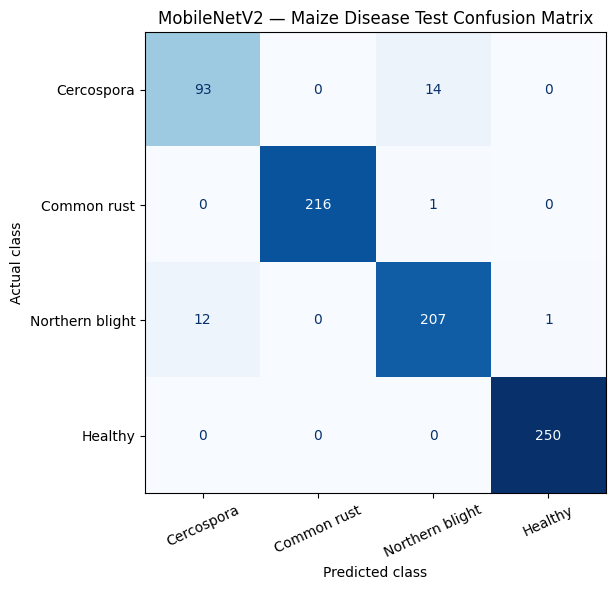

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

class_names = [
    "Cercospora",
    "Common rust",
    "Northern blight",
    "Healthy"
]

cm = confusion_matrix(
    y_true_ft,
    y_pred_ft,
    labels=list(range(4))
)

fig, ax = plt.subplots(figsize=(8, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=25,
    colorbar=False
)

ax.set_title("MobileNetV2 — Maize Disease Test Confusion Matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")

plt.tight_layout()
plt.show()

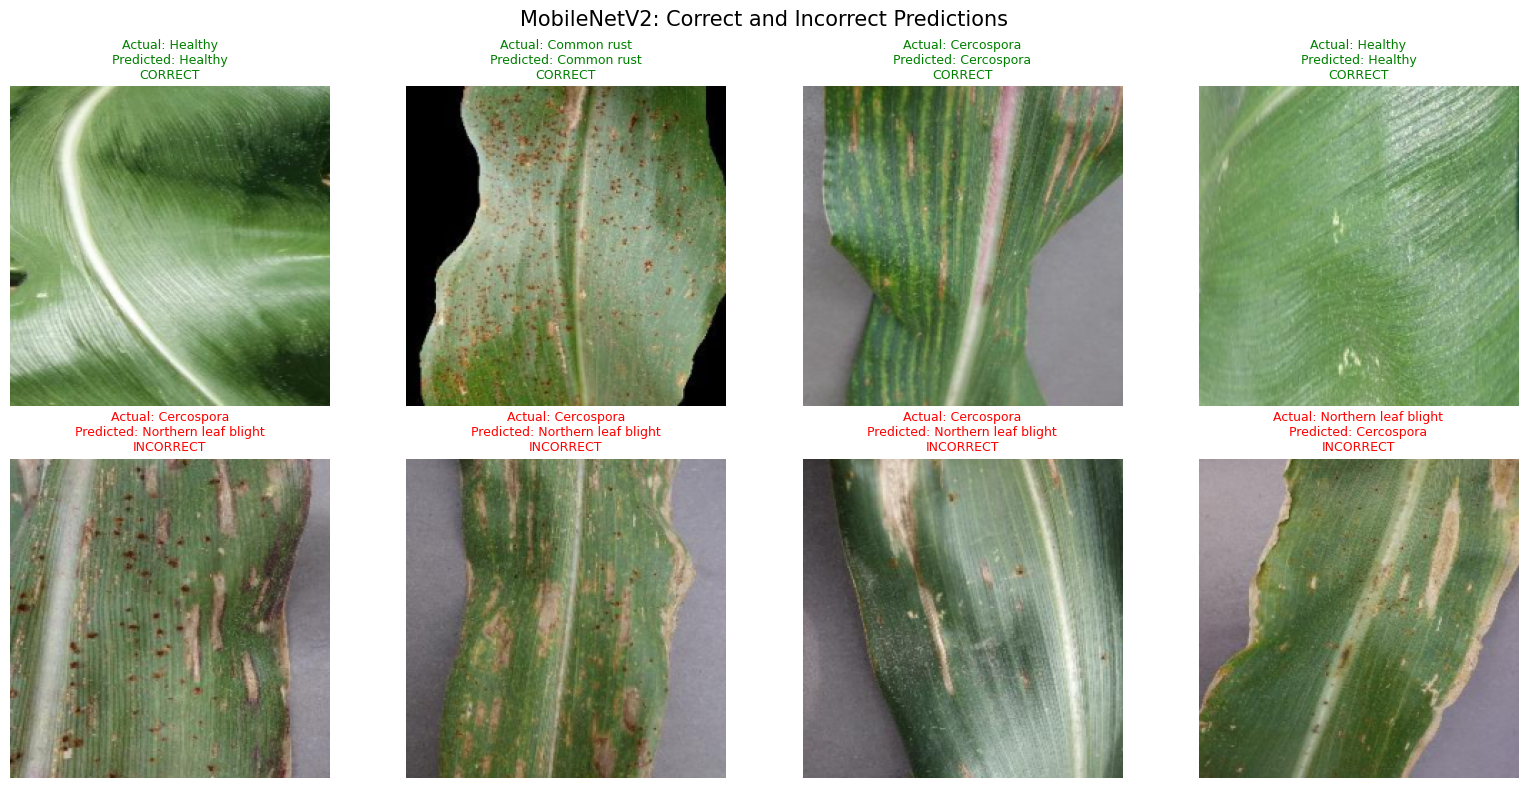

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random

# Use the test dataset and predictions already generated
class_names = [
    "Cercospora",
    "Common rust",
    "Northern leaf blight",
    "Healthy"
]

# Find correctly and incorrectly classified examples
correct_indices = [
    i for i in range(len(y_true_ft))
    if y_true_ft[i] == y_pred_ft[i]
]

wrong_indices = [
    i for i in range(len(y_true_ft))
    if y_true_ft[i] != y_pred_ft[i]
]

random.seed(42)

# Show 4 correct and 4 incorrect examples if available
selected_correct = random.sample(
    correct_indices, min(4, len(correct_indices))
)

selected_wrong = random.sample(
    wrong_indices, min(4, len(wrong_indices))
)

selected = selected_correct + selected_wrong

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, idx in zip(axes, selected):
    image, actual_label = test_dataset[idx]

    # Undo ImageNet normalization for display
    image = image.permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    image = np.clip(image * std + mean, 0, 1)

    predicted_label = y_pred_ft[idx]
    is_correct = actual_label == predicted_label

    ax.imshow(image)
    ax.set_title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"{'CORRECT' if is_correct else 'INCORRECT'}",
        color="green" if is_correct else "red",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(selected):]:
    ax.axis("off")

plt.suptitle(
    "MobileNetV2: Correct and Incorrect Predictions",
    fontsize=15
)
plt.tight_layout()
plt.show()

Saving corn image.jpg to corn image.jpg


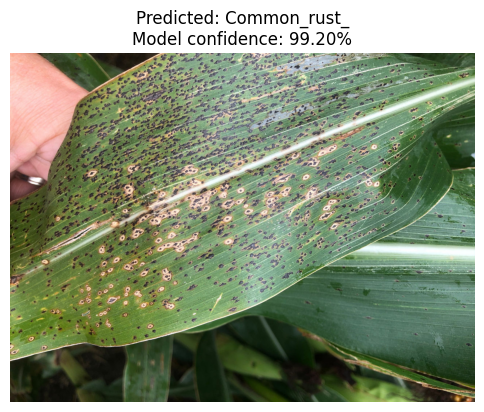

Prediction scores:
Cercospora_leaf_spot Gray_leaf_spot: 0.37%
Common_rust_: 99.20%
Northern_Leaf_Blight: 0.31%
healthy: 0.11%


In [ ]:
from PIL import Image
from google.colab import files
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torchvision import transforms

# Upload a maize leaf image
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))

    image = Image.open(filename).convert("RGB")

    # Preprocess the image exactly as during evaluation
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    input_tensor = transform(image).unsqueeze(0).to(device)

    # Predict
    model.eval()
    with torch.inference_mode():
        outputs = model(input_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]

    predicted_index = probabilities.argmax().item()
    predicted_class = full_train.classes[predicted_index]
    confidence = probabilities[predicted_index].item() * 100

    # Display image and prediction
    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Predicted: {predicted_class.replace('Corn_(maize)___', '')}\n"
        f"Model confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Prediction scores:")
    for i, class_name in enumerate(full_train.classes):
        readable_name = class_name.replace("Corn_(maize)___", "")
        print(f"{readable_name}: {probabilities[i].item() * 100:.2f}%")

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Maize_External_Test.zip to Maize_External_Test.zip


In [ ]:
import zipfile
from pathlib import Path

zip_file = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

external_dir = Path("/content/Maize_External_Test")

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(external_dir)

print("External dataset extracted to:", external_dir)
print("\nFolder contents:")

for folder in sorted(external_dir.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for p in folder.rglob("*")
            if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
        )
        print(f"{folder.name}: {count} images")

External dataset extracted to: /content/Maize_External_Test

Folder contents:
Maize_External_Test: 20 images


In [ ]:
from pathlib import Path

base_dir = Path("/content/Maize_External_Test")

# Find the directory that directly contains the four class folders
expected_classes = {
    "Cercospora",
    "Common_rust",
    "Healthy",
    "Northern_Leaf_Blight"
}

for path in [base_dir] + list(base_dir.iterdir()):
    if path.is_dir():
        subfolders = {p.name for p in path.iterdir() if p.is_dir()}
        if expected_classes.issubset(subfolders):
            external_dir = path
            break
else:
    raise FileNotFoundError("Could not find all four class folders.")

print("Correct dataset path:", external_dir)

for class_name in sorted(expected_classes):
    folder = external_dir / class_name
    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    ]
    print(f"{class_name}: {len(images)} images")

Correct dataset path: /content/Maize_External_Test/Maize_External_Test
Cercospora: 5 images
Common_rust: 5 images
Healthy: 5 images
Northern_Leaf_Blight: 5 images


Images evaluated: 20
External accuracy: 60.00%

Classification report:
                      precision    recall  f1-score   support

          Cercospora      0.333     0.400     0.364         5
         Common rust      0.500     0.400     0.444         5
Northern leaf blight      0.750     0.600     0.667         5
             Healthy      0.833     1.000     0.909         5

            accuracy                          0.600        20
           macro avg      0.604     0.600     0.596        20
        weighted avg      0.604     0.600     0.596        20



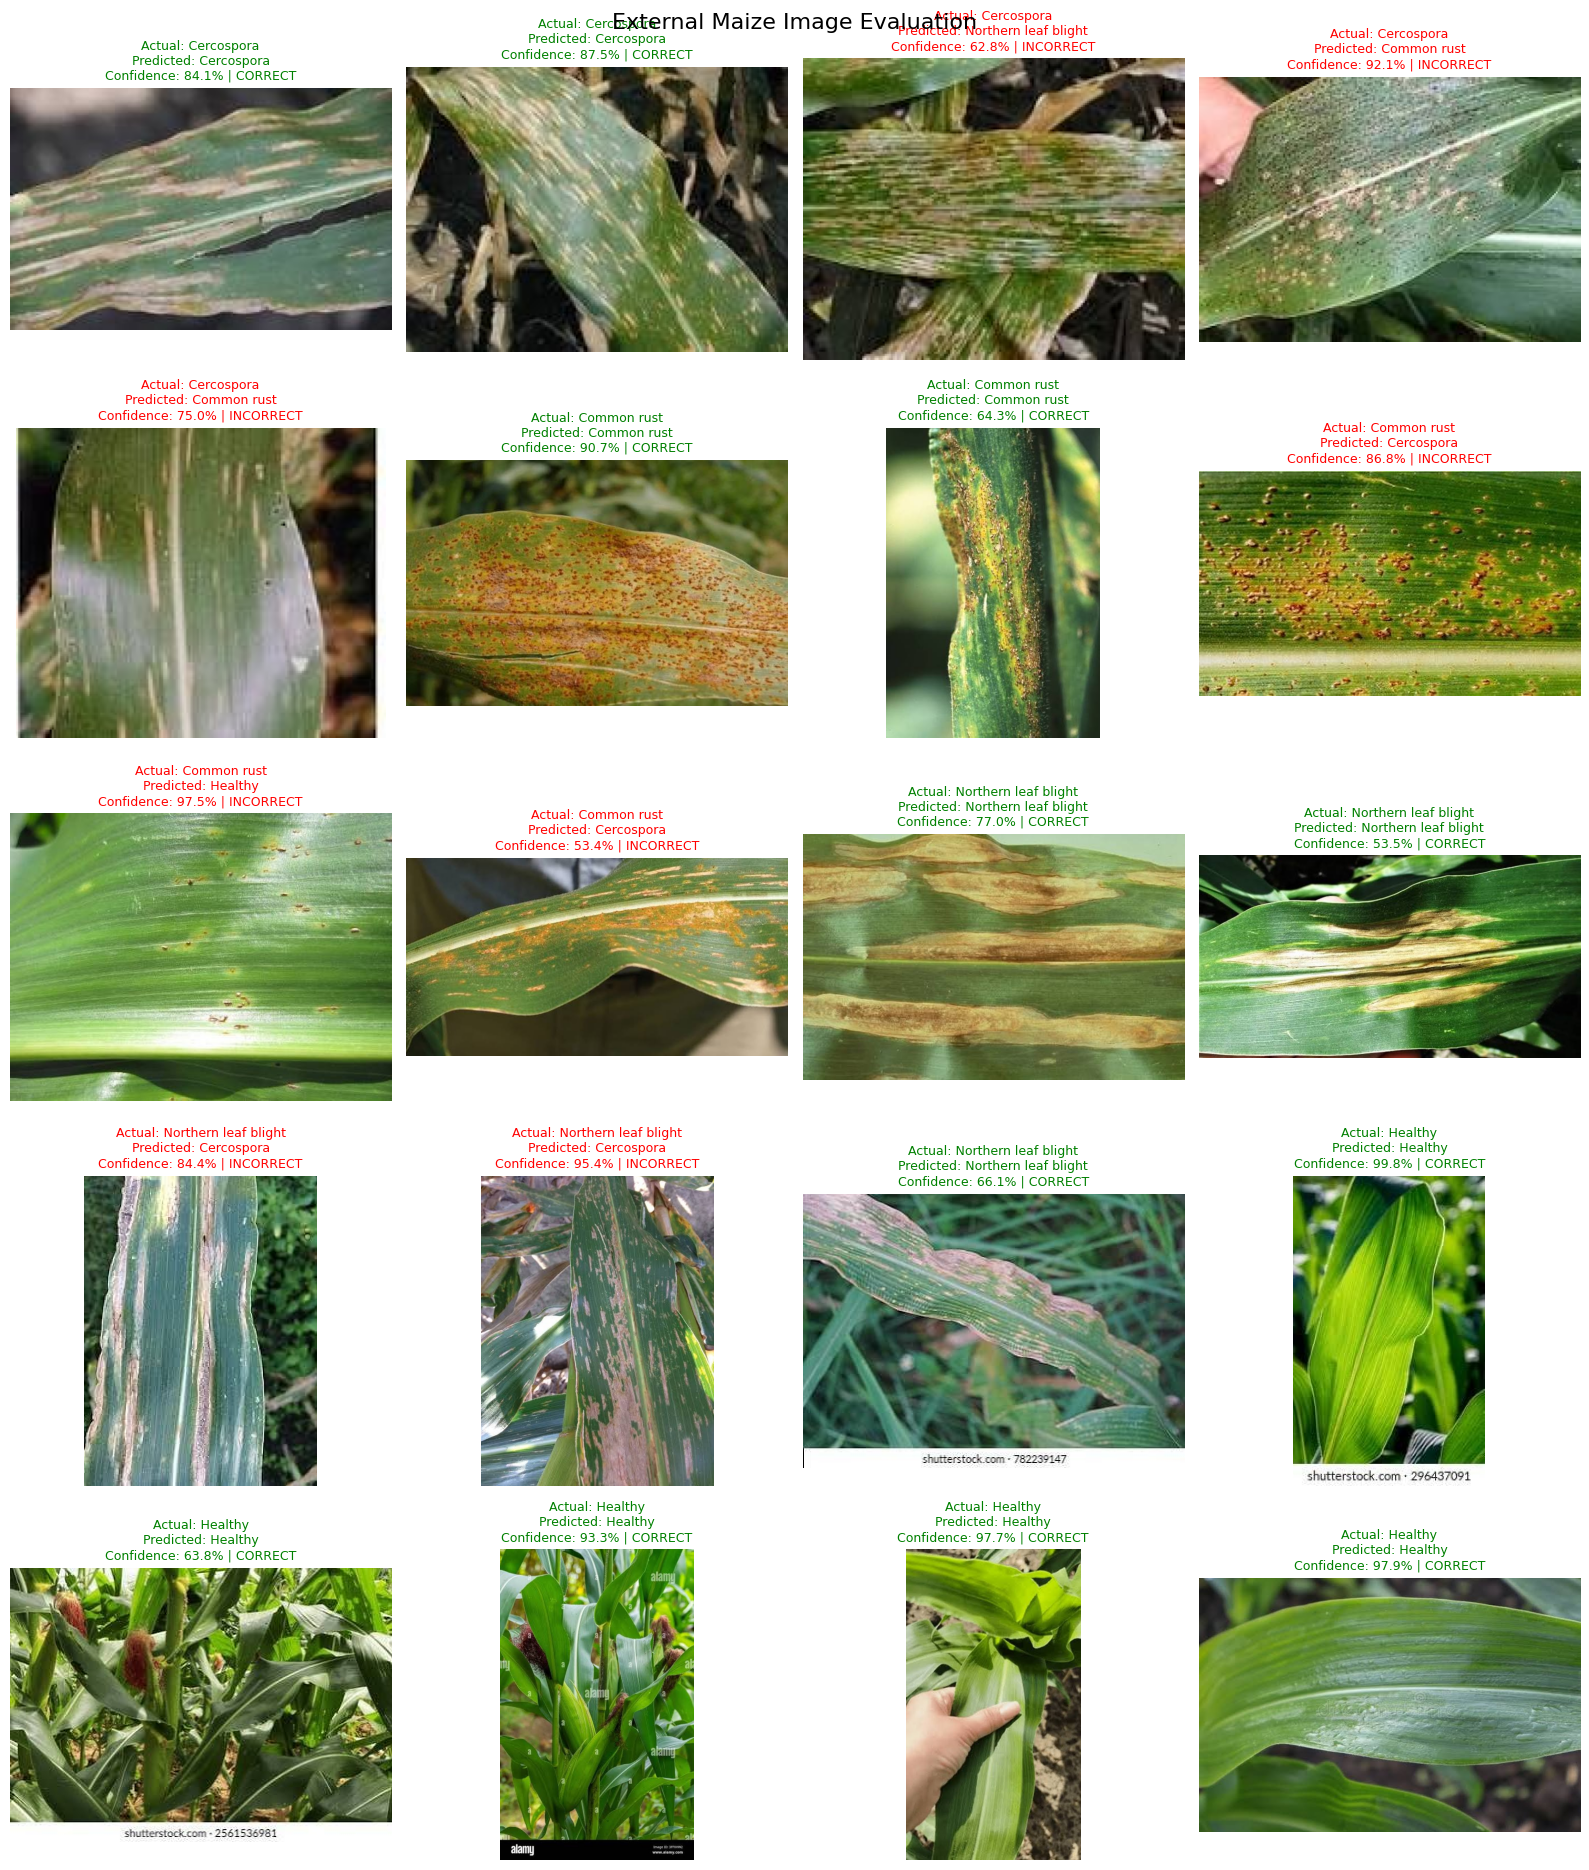

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from torchvision import transforms
from sklearn.metrics import accuracy_score, classification_report

# Match folder names to the model's class names
folder_to_label = {
    "Cercospora": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Common_rust": "Corn_(maize)___Common_rust_",
    "Northern_Leaf_Blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Healthy": "Corn_(maize)___healthy"
}

class_names = full_train.classes

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

results = []

model.eval()

for folder, actual_name in folder_to_label.items():
    folder_path = external_dir / folder

    for image_path in sorted(folder_path.iterdir()):
        if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
            continue

        image = Image.open(image_path).convert("RGB")
        input_tensor = transform(image).unsqueeze(0).to(device)

        with torch.inference_mode():
            logits = model(input_tensor)
            probs = F.softmax(logits, dim=1)[0]

        pred_idx = probs.argmax().item()

        results.append({
            "path": image_path,
            "image": image.copy(),
            "actual": class_names.index(actual_name),
            "predicted": pred_idx,
            "confidence": probs[pred_idx].item()
        })

y_true_ext = [r["actual"] for r in results]
y_pred_ext = [r["predicted"] for r in results]

print("Images evaluated:", len(results))
print("External accuracy:", f"{accuracy_score(y_true_ext, y_pred_ext):.2%}")
print("\nClassification report:")
print(classification_report(
    y_true_ext,
    y_pred_ext,
    labels=list(range(len(class_names))),
    target_names=[
        "Cercospora", "Common rust",
        "Northern leaf blight", "Healthy"
    ],
    zero_division=0,
    digits=3
))

# Display all 20 predictions in a gallery
fig, axes = plt.subplots(5, 4, figsize=(16, 19))
axes = axes.flatten()

short_names = [
    "Cercospora", "Common rust",
    "Northern leaf blight", "Healthy"
]

for ax, r in zip(axes, results):
    actual = short_names[r["actual"]]
    predicted = short_names[r["predicted"]]
    correct = r["actual"] == r["predicted"]

    ax.imshow(r["image"])
    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}\n"
        f"Confidence: {r['confidence']:.1%} | "
        f"{'CORRECT' if correct else 'INCORRECT'}",
        color="green" if correct else "red",
        fontsize=9
    )
    ax.axis("off")

plt.suptitle("External Maize Image Evaluation", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
import copy
import torch

# Start from the current best fine-tuned model
model.eval()

# Keep the same frozen/unfrozen layers as before.
# The previous setup unfroze the final four feature blocks.
for param in model.features.parameters():
    param.requires_grad = False

for block in model.features[-4:]:
    for param in block.parameters():
        param.requires_grad = True

for param in model.classifier.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam([
    {
        "params": [
            p for p in model.features.parameters()
            if p.requires_grad
        ],
        "lr": 0.000005
    },
    {
        "params": model.classifier.parameters(),
        "lr": 0.00005
    }
])

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
patience = 3
epochs_without_improvement = 0
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    model.features.eval()  # Keep feature BatchNorm layers stable

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    improved = val_loss < best_val_loss - 0.0001

    if improved:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(
            best_state,
            "/content/mobilenetv2_extended_best.pth"
        )
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

    if epochs_without_improvement >= patience:
        print("Early stopping: validation loss has stopped improving.")
        break

model.load_state_dict(best_state)
print("\nBest validation loss:", round(best_val_loss, 4))
print("Best checkpoint restored.")

Epoch 1/10 | Train Loss: 0.0733 | Train Acc: 96.97% | Val Loss: 0.0932 | Val Acc: 97.22%
Epoch 2/10 | Train Loss: 0.0684 | Train Acc: 97.26% | Val Loss: 0.1036 | Val Acc: 95.92%
Epoch 3/10 | Train Loss: 0.0688 | Train Acc: 97.34% | Val Loss: 0.0924 | Val Acc: 97.22%
Epoch 4/10 | Train Loss: 0.0661 | Train Acc: 97.51% | Val Loss: 0.0919 | Val Acc: 97.06%
Epoch 5/10 | Train Loss: 0.0614 | Train Acc: 97.75% | Val Loss: 0.0962 | Val Acc: 96.90%
Epoch 6/10 | Train Loss: 0.0668 | Train Acc: 97.59% | Val Loss: 0.0894 | Val Acc: 97.39%
Epoch 7/10 | Train Loss: 0.0633 | Train Acc: 97.79% | Val Loss: 0.0922 | Val Acc: 97.06%
Epoch 8/10 | Train Loss: 0.0597 | Train Acc: 97.87% | Val Loss: 0.0913 | Val Acc: 97.06%
Epoch 9/10 | Train Loss: 0.0546 | Train Acc: 98.00% | Val Loss: 0.0897 | Val Acc: 97.06%
Early stopping: validation loss has stopped improving.

Best validation loss: 0.0894
Best checkpoint restored.


In [ ]:
import torch

checkpoint_path = "/content/mobilenetv2_extended_best.pth"

state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model.eval()

print("Best extended-training checkpoint loaded.")
print("Ready for final test evaluation.")

Best extended-training checkpoint loaded.
Ready for final test evaluation.


In [ ]:
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()
y_true_extended = []
y_pred_extended = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        predictions = outputs.argmax(dim=1).cpu().tolist()

        y_pred_extended.extend(predictions)
        y_true_extended.extend(labels.tolist())

accuracy = accuracy_score(y_true_extended, y_pred_extended)

print("Test images:", len(y_true_extended))
print(f"Extended-training test accuracy: {accuracy:.2%}")

print("\nClassification report:")
print(classification_report(
    y_true_extended,
    y_pred_extended,
    target_names=[
        "Cercospora",
        "Common rust",
        "Northern leaf blight",
        "Healthy"
    ],
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true_extended, y_pred_extended))

Test images: 794
Extended-training test accuracy: 96.73%

Classification report:
                      precision    recall  f1-score   support

          Cercospora     0.8739    0.9065    0.8899       107
         Common rust     1.0000    0.9954    0.9977       217
Northern leaf blight     0.9491    0.9318    0.9404       220
             Healthy     0.9960    1.0000    0.9980       250

            accuracy                         0.9673       794
           macro avg     0.9547    0.9584    0.9565       794
        weighted avg     0.9676    0.9673    0.9674       794

Confusion matrix:
[[ 97   0  10   0]
 [  0 216   1   0]
 [ 14   0 205   1]
 [  0   0   0 250]]


In [ ]:
import torch
import torch.nn.functional as F
from PIL import Image
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report
from torchvision import transforms

folder_to_label = {
    "Cercospora": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Common_rust": "Corn_(maize)___Common_rust_",
    "Northern_Leaf_Blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Healthy": "Corn_(maize)___healthy"
}

class_names = full_train.classes

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

y_true_ext_new, y_pred_ext_new = [], []

model.eval()

with torch.inference_mode():
    for folder, actual_name in folder_to_label.items():
        for path in sorted((external_dir / folder).iterdir()):
            if path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
                continue

            image = Image.open(path).convert("RGB")
            x = transform(image).unsqueeze(0).to(device)

            prediction = model(x).argmax(dim=1).item()

            y_true_ext_new.append(class_names.index(actual_name))
            y_pred_ext_new.append(prediction)

print("External images:", len(y_true_ext_new))
print(f"External accuracy: {accuracy_score(y_true_ext_new, y_pred_ext_new):.2%}")

print(classification_report(
    y_true_ext_new,
    y_pred_ext_new,
    labels=list(range(4)),
    target_names=[
        "Cercospora", "Common rust",
        "Northern leaf blight", "Healthy"
    ],
    digits=3,
    zero_division=0
))

External images: 20
External accuracy: 60.00%
                      precision    recall  f1-score   support

          Cercospora      0.333     0.400     0.364         5
         Common rust      0.500     0.400     0.444         5
Northern leaf blight      0.750     0.600     0.667         5
             Healthy      0.833     1.000     0.909         5

            accuracy                          0.600        20
           macro avg      0.604     0.600     0.596        20
        weighted avg      0.604     0.600     0.596        20



In [ ]:

import pandas as pd
from pathlib import Path
from PIL import Image
import torch
from torchvision import transforms

folder_to_label = {
    "Cercospora": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Common_rust": "Corn_(maize)___Common_rust_",
    "Northern_Leaf_Blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Healthy": "Corn_(maize)___healthy"
}

display_names = {
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": "Cercospora",
    "Corn_(maize)___Common_rust_": "Common rust",
    "Corn_(maize)___Northern_Leaf_Blight": "Northern leaf blight",
    "Corn_(maize)___healthy": "Healthy"
}

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

rows = []
model.eval()

with torch.inference_mode():
    for folder, actual_label in folder_to_label.items():
        for path in sorted((external_dir / folder).iterdir()):
            if path.suffix.lower() not in {
                ".jpg", ".jpeg", ".png", ".webp"
            }:
                continue

            image = Image.open(path).convert("RGB")
            x = transform(image).unsqueeze(0).to(device)

            probabilities = torch.softmax(model(x), dim=1)[0]
            pred_idx = probabilities.argmax().item()
            actual_idx = full_train.classes.index(actual_label)

            rows.append({
                "Image": path.name,
                "Actual": display_names[actual_label],
                "Predicted": display_names[full_train.classes[pred_idx]],
                "Confidence": round(
                    probabilities[pred_idx].item() * 100, 2
                ),
                "Correct": pred_idx == actual_idx
            })

results_df = pd.DataFrame(rows)
display(results_df)


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:

from IPython.display import display as show_table

show_table(results_df)


,Image,Actual,Predicted,Confidence,Correct
0,WhatsApp Image 2026-10-14 at 11.24.02 PM.jpeg,Cercospora,Cercospora,91.47,True
1,WhatsApp Image 2026-10-14 at 11.24.12 PM.jpeg,Cercospora,Cercospora,90.56,True
2,WhatsApp Image 2026-10-14 at 11.24.28 PM.jpeg,Cercospora,Northern leaf blight,55.72,False
3,WhatsApp Image 2026-10-14 at 11.24.36 PM.jpeg,Cercospora,Common rust,91.87,False
4,WhatsApp Image 2026-10-14 at 11.24.44 PM.jpeg,Cercospora,Common rust,75.55,False
5,WhatsApp Image 2026-10-14 at 11.26.00 PM.jpeg,Common rust,Common rust,88.61,True
6,WhatsApp Image 2026-10-14 at 11.26.22 PM.jpeg,Common rust,Common rust,67.48,True
7,WhatsApp Image 2026-10-14 at 11.26.44 PM.jpeg,Common rust,Cercospora,94.98,False
8,WhatsApp Image 2026-10-14 at 11.27.10 PM.jpeg,Common rust,Healthy,98.70,False
9,WhatsApp Image 2026-10-14 at 11.27.50 PM.jpeg,Common rust,Cercospora,70.66,False


Classes: ['Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy']
Test images: 794

Test Accuracy: 96.73%

Classification Report:
                                                    precision    recall  f1-score   support

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8739    0.9065    0.8899       107
                       Corn_(maize)___Common_rust_     1.0000    0.9954    0.9977       217
               Corn_(maize)___Northern_Leaf_Blight     0.9491    0.9318    0.9404       220
                            Corn_(maize)___healthy     0.9960    1.0000    0.9980       250

                                          accuracy                         0.9673       794
                                         macro avg     0.9547    0.9584    0.9565       794
                                      weighted avg     0.9676    0.9673    0.9674       794



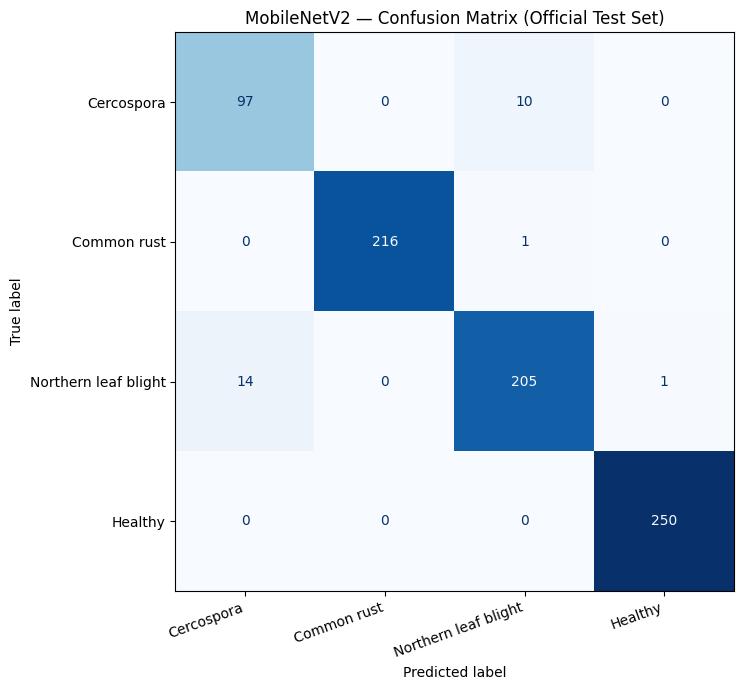

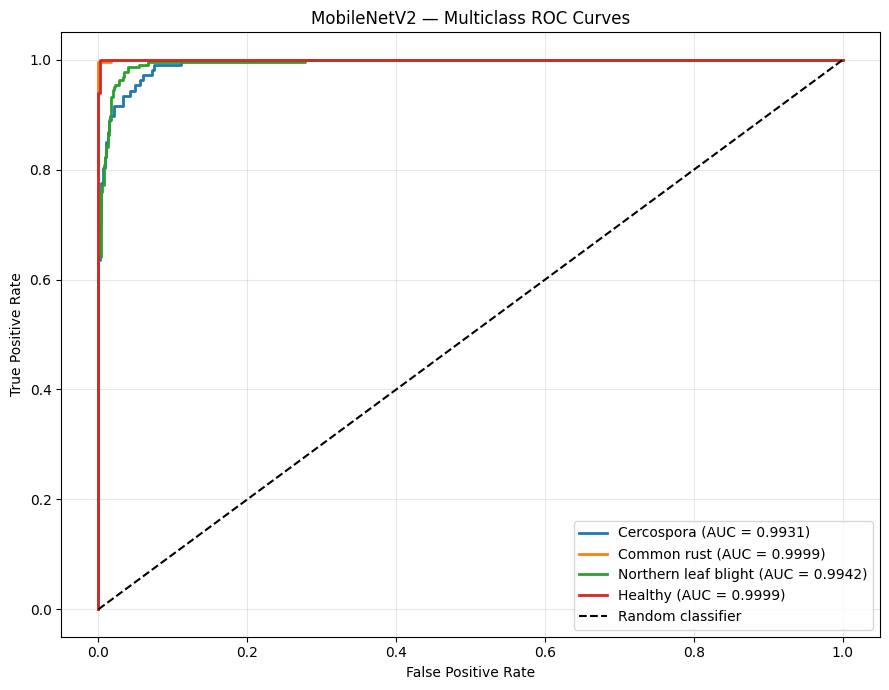


ROC-AUC per class:
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 0.9931
Corn_(maize)___Common_rust_: 0.9999
Corn_(maize)___Northern_Leaf_Blight: 0.9942
Corn_(maize)___healthy: 0.9999

Macro-average ROC-AUC: 0.9968


In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score
)
from sklearn.preprocessing import label_binarize

# 1. Load the official test dataset
test_dir = Path("/content/maize_vlm_test")

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = datasets.ImageFolder(
    test_dir, transform=test_transform
)
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False
)

class_names = test_dataset.classes
print("Classes:", class_names)
print("Test images:", len(test_dataset))

# 2. Load the best extended-training checkpoint
checkpoint_path = "/content/mobilenetv2_extended_best.pth"
model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)
model = model.to(device)
model.eval()

# 3. Collect actual labels and prediction probabilities
y_true, y_pred, y_prob = [], [], []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.softmax(logits, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(probs.argmax(dim=1).cpu().numpy())
        y_prob.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

# 4. Accuracy and classification report
accuracy = accuracy_score(y_true, y_pred)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# 5. Confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(class_names)))
)

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Cercospora", "Common rust",
        "Northern leaf blight", "Healthy"
    ]
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("MobileNetV2 — Confusion Matrix (Official Test Set)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(
    "/content/mobilenetv2_confusion_matrix.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# 6. Multiclass ROC curves (one-vs-rest)
n_classes = len(class_names)
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))

plt.figure(figsize=(9, 7))
auc_values = {}

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    class_auc = auc(fpr, tpr)
    auc_values[class_names[i]] = class_auc

    short_name = [
        "Cercospora", "Common rust",
        "Northern leaf blight", "Healthy"
    ][i]

    plt.plot(
        fpr, tpr, linewidth=2,
        label=f"{short_name} (AUC = {class_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("MobileNetV2 — Multiclass ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/content/mobilenetv2_roc_curve.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("\nROC-AUC per class:")
for name, score in auc_values.items():
    print(f"{name}: {score:.4f}")

print(
    "\nMacro-average ROC-AUC:",
    f"{roc_auc_score(y_true_bin, y_prob, average='macro'):.4f}"
)


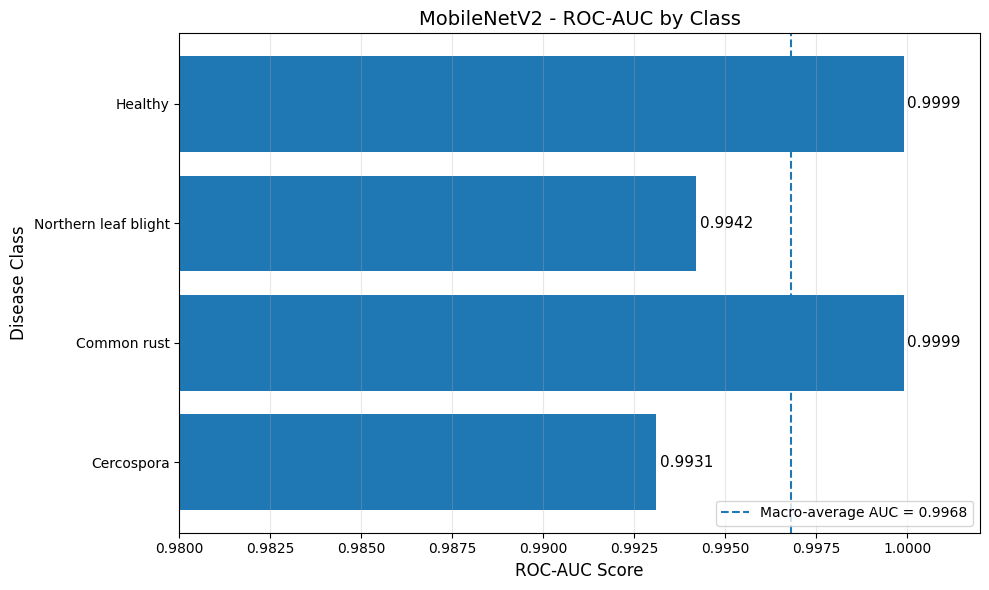

Macro-average ROC-AUC: 0.9968
Chart saved to /content/mobilenetv2_roc_auc_summary.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ROC-AUC values from your MobileNetV2 evaluation
classes = [
    "Cercospora",
    "Common rust",
    "Northern leaf blight",
    "Healthy"
]

auc_values = [0.9931, 0.9999, 0.9942, 0.9999]
macro_auc = 0.9968

# Create the bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(classes, auc_values)

# Display values on each bar
for bar, value in zip(bars, auc_values):
    ax.text(
        value + 0.0001,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        fontsize=11
    )

# Chart formatting
ax.set_xlim(0.98, 1.002)
ax.set_xlabel("ROC-AUC Score", fontsize=12)
ax.set_ylabel("Disease Class", fontsize=12)
ax.set_title("MobileNetV2 - ROC-AUC by Class", fontsize=14)

ax.axvline(
    macro_auc,
    linestyle="--",
    label=f"Macro-average AUC = {macro_auc:.4f}"
)

ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save a high-resolution image in Colab
plt.savefig(
    "/content/mobilenetv2_roc_auc_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Macro-average ROC-AUC: {macro_auc:.4f}")
print("Chart saved to /content/mobilenetv2_roc_auc_summary.png")

In [1]:
from google.colab import files

files.download("/content/mobilenetv2_confusion_matrix.png")
files.download("/content/mobilenetv2_roc_curve.png")
files.download("/content/mobilenetv2_roc_auc_summary.png")

FileNotFoundError: Cannot find file: /content/mobilenetv2_confusion_matrix.png

In [3]:
import os
from pathlib import Path

for folder in ["/content", "/content/drive/MyDrive"]:
    if os.path.exists(folder):
        print(f"\nChecking: {folder}")
        for p in Path(folder).rglob("*"):
            if p.is_file() and any(
                word in p.name.lower()
                for word in ["confusion_matrix", "roc_curve", "roc_auc"]
            ):
                print(p)



Checking: /content


In [4]:
import os

paths = [
    "/content/mobilenetv2_extended_best.pth",
    "/content/mobilenetv2_finetuned_final.pth",
    "/content/maize_vlm_test",
    "/content/Maize_External_Test"
]

for path in paths:
    print(f"{'FOUND' if os.path.exists(path) else 'NOT FOUND'}: {path}")

NOT FOUND: /content/mobilenetv2_extended_best.pth
NOT FOUND: /content/mobilenetv2_finetuned_final.pth
NOT FOUND: /content/maize_vlm_test
NOT FOUND: /content/Maize_External_Test
